# Stratified + heteroskedastic transformation models

[04_interacting_terms](04_interacting_terms.ipynb) let the *shape* of the
conditional distribution change with a covariate $x$ through the tensor
product $h(y \mid x) = (a(y) \otimes b(x))^\top \mathrm{vec}(\Theta)$.
[05_scaling_terms](05_scaling_terms.ipynb) let its *spread* change with a
second covariate $x_s$ through the positive factor
$\exp(\tfrac{1}{2} x_s^\top \gamma)$.  This vignette combines the two:

$$
h(y \mid x, x_s) \;=\; \bigl(a(y) \otimes b(x)\bigr)^{\!\top}
\mathrm{vec}(\Theta)\;\cdot\;\exp\!\bigl(\tfrac{1}{2}\, x_s^\top \gamma\bigr).
$$

The stratified (interacting) baseline is *multiplied* by the scaling
factor; there is no additive $x_d^\top\beta$ shift on this path — every
effect of $x$ flows through $\Theta$.  The design (parameter layout
$\theta = [\mathrm{vec}_C(\Theta) \mid \gamma]$, the unchanged column-wise
monotonicity constraint with $\gamma$ left unconstrained, and the R parity
strategy) is recorded in
[ADR 0003](../adr/0003-scaling-with-interaction.md).  The R analogue is
the `stram` model `tram::Coxph(y | x ~ 1 | x_s)` /
`mlt::ctm(response, interacting, scaling)`.

We work through a **non-proportional Cox model with a scaled baseline**
(Bernstein-$t$ $\otimes$ Bernstein-$x$, scaled by $x_s$):

1. simulate survival times whose log-cumulative hazard changes slope with
   $x$ *and* is stretched by $x_s$;
2. fit it with `Coxph(interacting=..., scaling=...)` and test $\gamma$
   against the unscaled interacting model;
3. interpret `Theta_` and `gamma_`;
4. predict survival curves and quantiles with `X_scale_new`;
5. check parity with R on the `stram` reference fixture.

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import chi2

import mltpy
from mltpy import BernsteinBasis

rng = np.random.default_rng(111)
plt.rcParams["figure.dpi"] = 110
REF_DIR = Path("../../reference")  # repo-relative path to reference fixtures

## 1. Simulated data

`Coxph` uses the minimum-extreme-value link,
$\log[-\log S(t \mid x, x_s)] = h(t \mid x, x_s)$.  We choose a
Gompertz-type truth whose log-cumulative hazard is linear in $t$, with a
slope that grows with the stratifying covariate $x \in [0, 1]$:

$$
h_0(t \mid x) = (2 + 2x)(t - 10) + x,
\qquad
h(t \mid x, x_s) = h_0(t \mid x)\, \exp\!\bigl(\tfrac{1}{2}\,\gamma\, x_s\bigr),
\quad \gamma = 0.8 .
$$

* $x$ changes the *shape*: steeper $h_0$ means a hazard that rises faster,
  so survival curves at different $x$ cross (here at $t = 9.5$) — not a
  proportional-hazards effect.
* $x_s \sim \mathcal{U}(-1.5, 1.5)$ *stretches* $h_0$ around its zero:
  $x_s > 0$ concentrates the event times, $x_s < 0$ spreads them out.

Because $h(T \mid x, x_s)$ follows the minimum extreme value
distribution, we draw $Z = \log(-\log U)$ and invert $h$ in closed form.
The interaction likelihood covers exact (uncensored) event times only, so
every time is observed.

In [2]:
n = 800
gamma_true = 0.8
x = rng.uniform(0.0, 1.0, size=n)       # stratifying / interacting covariate
x_s = rng.uniform(-1.5, 1.5, size=n)    # scaling covariate


def h0_true(t, x):
    # True unscaled log-cumulative hazard h_0(t | x).
    return (2.0 + 2.0 * x) * (t - 10.0) + x


Z = np.log(-np.log(rng.uniform(size=n)))  # min-extreme-value draws
t = 10.0 + (Z / np.exp(0.5 * gamma_true * x_s) - x) / (2.0 + 2.0 * x)

support = (float(t.min()) - 0.25, float(t.max()) + 0.25)
X_s = x_s.reshape(-1, 1)  # scaling design, shape (n, q_s) with q_s = 1
print(f"n={n},  t in [{t.min():.2f}, {t.max():.2f}],  "
      f"support=({support[0]:.2f}, {support[1]:.2f})")

n=800,  t in [5.66, 10.76],  support=(5.41, 11.01)


## 2. Fitting

### Stratified baseline only (the 04 route)

`Coxph(interacting=BernsteinBasis(...))` fits
$h(t \mid x) = (a(t) \otimes b(x))^\top \mathrm{vec}(\Theta)$: a
Bernstein polynomial of order 2 in $t$ for every Bernstein basis function
of order 2 in $x$, so $\Theta$ is a $3 \times 3$ matrix.  The true
$h_0$ is bilinear in $(t, x)$, so it lies exactly in this span.

**Solver.** We fit with `solver="trust-constr"`.  The stratified-only
model is misspecified here (it ignores $x_s$), and its optimum sits on the
monotonicity boundary; on the interaction path the default `"auglag"`
solver can stop short of such boundary optima while still reporting
`converged=True`.  The column increments printed below show the active
boundary (a zero increment), and a cell further down cross-checks the
scaled fit, whose optimum is interior, against the default solver.

In [3]:
ORDER_T, ORDER_X = 2, 2
x_basis = BernsteinBasis(order=ORDER_X, support=(0.0, 1.0))
config = mltpy.OptimizerConfig(solver="trust-constr", random_state=0)

strat = mltpy.Coxph(
    support=support, order=ORDER_T, interacting=x_basis, optimizer_config=config
).fit(t, X=x)
print(f"log-lik (stratified only): {strat.result_.log_likelihood:.3f}  "
      f"(k={strat.n_free_params_})")
# Column-wise increments D @ Theta[:, j] >= 0; a zero entry is an active
# monotonicity constraint.
print("column increments of strat.Theta_:")
print(np.round(np.diff(strat.Theta_, axis=0), 4))

log-lik (stratified only): -480.605  (k=9)
column increments of strat.Theta_:
[[ 5.9722  9.7116  0.    ]
 [ 6.5908  5.2619 12.9238]]


### Stratified + scaled baseline

Adding `scaling=X_s` appends the $\gamma$ block.  R `tram` labels this
combination "highly experimental", and mltpy mirrors that with a
`UserWarning` at fit time — we capture and print it here once, then
silence it for the remaining fits in this notebook.

`summary()` tabulates $\gamma$ with a Wald standard error under
*Scaling coefficients*; $\Theta$ is not tabulated (it has no shift-model
interpretation — see the next section).

In [4]:
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    model = mltpy.Coxph(
        support=support,
        order=ORDER_T,
        interacting=x_basis,
        scaling=X_s,
        optimizer_config=config,
    ).fit(t, X=x)
for w in caught:
    print(f"{w.category.__name__}: {w.message}\n")
# Seen once — silence it for the later scaled fits.
warnings.filterwarnings("ignore", message="scaling= with InteractionBasis")

print(model.summary())


Model:        Coxph
Support:      (5.40561541807002, 11.008059182438737)
Basis order:  2
Fitted:       Yes
Log-lik:      -396.2511
AIC:          812.5023
BIC:          859.3484
Converged:    Yes
n_restarts:   0

Coefficients:
Scaling coefficients:
          Estimate  Std. Error   z value   Pr(>|z|)
  X1        0.8593      0.0659    13.041  7.149e-39


### Likelihood-ratio test on $\gamma$

The stratified-only model is the special case $\gamma = 0$, so the deviance
$2(\ell_{\text{scaled}} - \ell_{\text{strat}})$ is asymptotically
$\chi^2_{q_s}$.

In [5]:
ll_strat = strat.result_.log_likelihood
ll_scaled = model.result_.log_likelihood
df = model.n_free_params_ - strat.n_free_params_
lr = 2.0 * (ll_scaled - ll_strat)
print(f"log-lik stratified only : {ll_strat:.3f}  (k={strat.n_free_params_})")
print(f"log-lik strat + scaling : {ll_scaled:.3f}  (k={model.n_free_params_})")
print(f"LR statistic            : {lr:.2f} on {df} df,  p = {chi2.sf(lr, df=df):.2e}")

log-lik stratified only : -480.605  (k=9)
log-lik strat + scaling : -396.251  (k=10)
LR statistic            : 168.71 on 1 df,  p = 1.42e-38


### Checking the fit with a second solver

Because the path is experimental, it is worth confirming the optimum with
an independent solver.  SciPy's `"trust-constr"` and the default PHR
augmented Lagrangian (`"auglag"`, which mirrors R `mlt`) should agree on
the maximised log-likelihood.  Treat the `converged` flag as
informational and compare $\ell$ (and $\gamma$) directly.

In [6]:
model_auglag = mltpy.Coxph(
    support=support,
    order=ORDER_T,
    interacting=x_basis,
    scaling=X_s,
    optimizer_config=mltpy.OptimizerConfig(solver="auglag", random_state=0),
).fit(t, X=x)

for name, fit in [("trust-constr", model), ("auglag", model_auglag)]:
    print(f"{name:12s} : log-lik = {fit.result_.log_likelihood:.6f},  "
          f"gamma = {fit.gamma_[0]:.6f}")
np.testing.assert_allclose(
    model.result_.log_likelihood, model_auglag.result_.log_likelihood, rtol=1e-6
)
np.testing.assert_allclose(model.gamma_, model_auglag.gamma_, rtol=1e-4)

trust-constr : log-lik = -396.251132,  gamma = 0.859278
auglag       : log-lik = -396.251132,  gamma = 0.859279


## 3. Interpreting `Theta_` and `gamma_`

### `Theta_`: the stratified baseline

`theta_` is laid out as $[\mathrm{vec}_C(\Theta) \mid \gamma]$ (ADR 0003,
Decision 1): the first $p \cdot q$ entries are the row-major flattening of
the $(p, q)$ coefficient matrix, followed by the $q_s$ scaling
coefficients.  `Theta_` reshapes the leading block and `gamma_` returns the
trailing one — never slice `theta_` by hand.

* **Row $i$** belongs to the $i$-th Bernstein basis function in $t$,
  **column $j$** to the $j$-th Bernstein basis function in $x$.
* Bernstein coefficients are *control points*: $\Theta_{ij}$ is
  (approximately) the value of the unscaled baseline $h_0(t_i \mid x_j)$
  at the grid point $t_i = a + i\,(b-a)/(p-1)$,
  $x_j = j/(q-1)$.  For a bilinear truth like ours the relationship is
  exact, so we can print the true $\Theta$ alongside the estimate.  The
  first row sits at $t = a$, deep in the sparse left tail of the event
  times, so it is estimated far less precisely than the others — the
  standard errors below make that visible.
* Each **column** is the coefficient vector of a monotone Bernstein
  polynomial in $t$; the column-wise constraint
  $D\,\Theta_{\cdot j} \ge 0$ is what keeps $h$ increasing in $t$ for
  every $x$.
* At the endpoints of the $x$-support only one $x$-basis function is
  active, so column 0 *is* the baseline at $x = 0$ and the last column
  *is* the baseline at $x = 1$.

In [7]:
Theta = model.Theta_
p, q = Theta.shape
q_s = model.gamma_.size
print(f"theta_ has length {model.theta_.size} = p*q + q_s = {p}*{q} + {q_s}")

a, b = support
t_ctrl = a + np.arange(p) * (b - a) / (p - 1)
x_ctrl = np.arange(q) / (q - 1)
Theta_true = h0_true(t_ctrl[:, None], x_ctrl[None, :])

np.set_printoptions(precision=3, suppress=True)
print("\nTheta_ (rows: t control points, cols: x control points)")
print(Theta)
print("\nWald standard errors of Theta_")
print(model.standard_errors()[: p * q].reshape(p, q))
print("\ntrue h_0(t_i | x_j)")
print(Theta_true)

# Column-wise monotonicity holds for every x-basis column.
assert np.all(np.diff(Theta, axis=0) >= -1e-8)

theta_ has length 10 = p*q + q_s = 3*3 + 1

Theta_ (rows: t control points, cols: x control points)
[[-14.279  -8.55  -12.218]
 [ -3.295  -5.264  -7.735]
 [  1.943   3.679   5.294]]

Wald standard errors of Theta_
[[4.55  7.986 6.18 ]
 [1.271 2.389 1.997]
 [0.349 0.729 0.665]]

true h_0(t_i | x_j)
[[ -9.189 -13.283 -17.378]
 [ -3.586  -4.879  -6.173]
 [  2.016   3.524   5.032]]


In [8]:
# Column 0 / last column reproduce the unscaled baseline at x = 0 / x = 1.
t_grid = np.linspace(a + 0.05, b - 0.05, 5)
y_basis = BernsteinBasis(order=ORDER_T, support=support)
X_s_zero = np.zeros((t_grid.size, 1))
for j, x_end in [(0, 0.0), (q - 1, 1.0)]:
    via_theta = y_basis.evaluate(t_grid) @ Theta[:, j]
    via_predict = model.predict(
        t_grid, X_new=np.full(t_grid.size, x_end), X_scale_new=X_s_zero, what="trafo"
    )
    np.testing.assert_allclose(via_theta, via_predict, atol=1e-10)
    print(f"column {j} == h(t | x={x_end:.0f}, x_s=0) on the grid  ✓")

column 0 == h(t | x=0, x_s=0) on the grid  ✓
column 2 == h(t | x=1, x_s=0) on the grid  ✓


### `gamma_`: the scaling factor

The scaling term multiplies the *whole* stratified baseline by
$\exp(\tfrac{1}{2} x_s \gamma)$.  So, for every $t$ and every $x$,

$$
\frac{h(t \mid x, x_s)}{h(t \mid x, 0)} = \exp\!\bigl(\tfrac{1}{2}\, x_s \gamma\bigr),
$$

a ratio that depends on $x_s$ alone.  The $\tfrac{1}{2}$ is not
cosmetic: it is the $\sqrt{\exp(\cdot)}$ of `mlt::ctm`'s shift-scale
model, and it makes `gamma_` sign- **and** magnitude-aligned with R's
`scl_` coefficient (no flip, no factor 2 when porting a `tram` fit).
$\gamma > 0$ means larger $x_s$ steepens $h$ (tighter, earlier-
concentrated event times); $\gamma < 0$ flattens it.

In [9]:
gamma_hat = model.gamma_[0]
lo, hi = model.confint()[-1]  # gamma is the last entry of theta_
print(f"gamma_ = {gamma_hat:.3f}   95% Wald CI [{lo:.3f}, {hi:.3f}]   "
      f"(truth {gamma_true})")
print(f"feature_names_scaling_ = {model.feature_names_scaling_}\n")

x_grid = np.full(t_grid.size, 0.3)
h_ref = model.predict(t_grid, X_new=x_grid, X_scale_new=X_s_zero, what="trafo")
for xs_val in (-1.0, 1.0):
    X_scale = np.full((t_grid.size, 1), xs_val)
    h_xs = model.predict(t_grid, X_new=x_grid, X_scale_new=X_scale, what="trafo")
    ratio = h_xs / h_ref
    factor = np.exp(0.5 * xs_val * gamma_hat)
    np.testing.assert_allclose(ratio, factor, rtol=1e-12)
    print(f"x_s = {xs_val:+.0f}:  h(t|x,x_s) / h(t|x,0) = {ratio[0]:.4f} at every t  "
          f"= exp(0.5 * x_s * gamma_) = {factor:.4f}")

gamma_ = 0.859   95% Wald CI [0.730, 0.988]   (truth 0.8)
feature_names_scaling_ = ['X1']

x_s = -1:  h(t|x,x_s) / h(t|x,0) = 0.6507 at every t  = exp(0.5 * x_s * gamma_) = 0.6507
x_s = +1:  h(t|x,x_s) / h(t|x,0) = 1.5367 at every t  = exp(0.5 * x_s * gamma_) = 1.5367


### What the factor does to the curves

Multiplying $h$ by a positive constant *pivots* it around its zero.  On the
survival scale $S = \exp(-e^{h})$, the zero of $h$ is the level
$S = e^{-1} \approx 0.368$: for a fixed $x$, every $x_s$-curve passes
through the same point there and the curves **cross** — the scaling term
on its own already breaks proportional hazards.  The stratified part adds
a second, independent departure: the curves for different $x$ (at fixed
$x_s$) cross where their baselines intersect.

* **Left:** $h(t \mid x=0.5, x_s)$ for three $x_s$ — a fan through the
  common zero.
* **Middle:** the corresponding survival curves, crossing at
  $S = e^{-1}$.
* **Right:** survival at $x = 0, 0.5, 1$ for $x_s = 0$ (solid) against the
  true curves (dotted).  The true curves all cross at $t = 9.5$ (dashed), where
  $h_0(9.5 \mid x) = -1$ for every $x$; the fitted curves cross close to it.

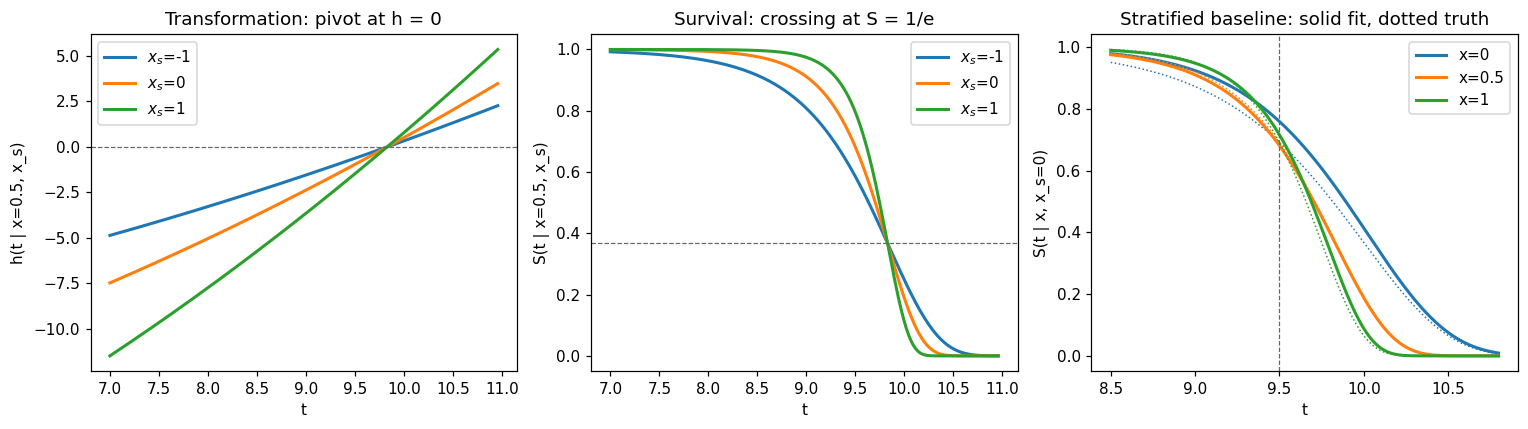

In [10]:
t_fine = np.linspace(7.0, min(11.0, b - 0.05), 300)
ones = np.ones(t_fine.size)
xs_vals = (-1.0, 0.0, 1.0)
fig, (ax_h, ax_s, ax_x) = plt.subplots(1, 3, figsize=(14, 4))

for i, xs_val in enumerate(xs_vals):
    X_scale = np.full((t_fine.size, 1), xs_val)
    h_curve = model.predict(t_fine, X_new=0.5 * ones, X_scale_new=X_scale, what="trafo")
    S_curve = model.survival(t_fine, X=0.5 * ones, X_scale=X_scale)
    ax_h.plot(t_fine, h_curve, color=f"C{i}", lw=2, label=f"$x_s$={xs_val:g}")
    ax_s.plot(t_fine, S_curve, color=f"C{i}", lw=2, label=f"$x_s$={xs_val:g}")

ax_h.axhline(0.0, color="0.4", lw=0.8, ls="--")
ax_h.set(xlabel="t", ylabel="h(t | x=0.5, x_s)", title="Transformation: pivot at h = 0")
ax_h.legend()
ax_s.axhline(np.exp(-1.0), color="0.4", lw=0.8, ls="--")
ax_s.set(xlabel="t", ylabel="S(t | x=0.5, x_s)", title="Survival: crossing at S = 1/e")
ax_s.legend()

t_zoom = np.linspace(8.5, min(10.8, b - 0.05), 300)
for i, x_val in enumerate((0.0, 0.5, 1.0)):
    S_hat = model.survival(
        t_zoom, X=np.full(t_zoom.size, x_val), X_scale=np.zeros((t_zoom.size, 1))
    )
    S_true = np.exp(-np.exp(h0_true(t_zoom, x_val)))
    ax_x.plot(t_zoom, S_hat, color=f"C{i}", lw=2, label=f"x={x_val:g}")
    ax_x.plot(t_zoom, S_true, color=f"C{i}", lw=1, ls=":")
ax_x.axvline(9.5, color="0.4", lw=0.8, ls="--")
ax_x.set(xlabel="t", ylabel="S(t | x, x_s=0)",
         title="Stratified baseline: solid fit, dotted truth")
ax_x.legend()
fig.tight_layout()
plt.show()

## 4. Prediction with `X_scale_new`

Every prediction on a scaled fit needs the scaling design for the new rows:
`predict(..., X_scale_new=...)` and `survival` / `hazard(..., X_scale=...)`
take an array of shape $(m, q_s)$, parallel to `X_new`.  Leaving it out is
an error rather than a silent $x_s = 0$:

In [11]:
try:
    model.predict(np.array([9.0]), X_new=np.array([0.5]), what="survivor")
except ValueError as err:
    print(f"ValueError: {err}")

ValueError: Model was fitted with scaling=; X_scale_new must be provided (shape (m, 1)).


### Quantiles on a grid of $(x, x_s)$

`predict(p, ..., what="quantile")` inverts $h(\cdot \mid x, x_s)$ row by
row, with a bracket derived from $h(a \mid x)$ and $h(b \mid x)$ rescaled
by the row's factor.  Below we compute the median survival time for every
combination of three $x$ and three $x_s$ values and compare it with the
closed-form truth
$t_{0.5} = 10 + \bigl(\log\log 2 \,/\, e^{\gamma x_s/2} - x\bigr) / (2 + 2x)$.

In [12]:
xx, ss = np.meshgrid([0.1, 0.5, 0.9], [-1.0, 0.0, 1.0], indexing="ij")
x_new = xx.ravel()
X_scale_new = ss.reshape(-1, 1)  # shape (m, q_s)

med_hat = model.predict(np.full(x_new.size, 0.5), X_new=x_new,
                        X_scale_new=X_scale_new, what="quantile")
z_med = np.log(np.log(2.0))
f_true = np.exp(0.5 * gamma_true * ss.ravel())
med_true = 10.0 + (z_med / f_true - x_new) / (2.0 + 2.0 * x_new)

print("   x    x_s   median (mltpy)   median (truth)")
for xv, sv, m_hat, m_true in zip(x_new, ss.ravel(), med_hat, med_true):
    print(f"  {xv:.1f}  {sv:+.0f}      {m_hat:8.3f}         {m_true:8.3f}")

# Round trip: S(Q(p | x, x_s) | x, x_s) = 1 - p.
S_at_med = model.survival(med_hat, X=x_new, X_scale=X_scale_new)
np.testing.assert_allclose(S_at_med, 0.5, rtol=1e-6)

   x    x_s   median (mltpy)   median (truth)
  0.1  -1         9.756            9.706
  0.1  +0         9.837            9.788
  0.1  +1         9.891            9.843
  0.5  -1         9.637            9.651
  0.5  +0         9.704            9.711
  0.5  +1         9.748            9.751
  0.9  -1         9.630            9.619
  0.9  +0         9.683            9.667
  0.9  +1         9.718            9.699


### The $x_s$-invariant quantile

The pivot from Section 3 has a direct prediction-side consequence.  At
probability $p^\star = 1 - e^{-1} \approx 0.632$ the quantile solves
$h = \log(-\log(1 - p^\star)) = 0$, and zero times any positive factor is
still zero — so $Q(p^\star \mid x, x_s)$ **does not depend on $x_s$** at
all.  It still depends on $x$, through the stratified baseline (truth:
$t^\star(x) = 10 - x / (2 + 2x)$).  Quantiles at any other $p$ move with
$x_s$.

In [13]:
p_star = 1.0 - np.exp(-1.0)
xs_sweep = np.array([-1.5, -0.5, 0.5, 1.5]).reshape(-1, 1)
for xv in (0.1, 0.5, 0.9):
    x_rep = np.full(xs_sweep.shape[0], xv)
    q_star = model.predict(np.full(x_rep.size, p_star), X_new=x_rep,
                           X_scale_new=xs_sweep, what="quantile")
    q_90 = model.predict(np.full(x_rep.size, 0.9), X_new=x_rep,
                         X_scale_new=xs_sweep, what="quantile")
    np.testing.assert_allclose(q_star, q_star[0], rtol=1e-8)
    print(f"x={xv}:  Q(0.632) = {q_star[0]:.3f} for every x_s "
          f"(truth {10 - xv / (2 + 2 * xv):.3f});   "
          f"Q(0.9) over x_s = {np.round(q_90, 3)}")

x=0.1:  Q(0.632) = 9.991 for every x_s (truth 9.955);   Q(0.9) over x_s = [10.686 10.438 10.279 10.178]
x=0.5:  Q(0.632) = 9.829 for every x_s (truth 9.833);   Q(0.9) over x_s = [10.355 10.173 10.054  9.976]
x=0.9:  Q(0.632) = 9.782 for every x_s (truth 9.763);   Q(0.9) over x_s = [10.195 10.053  9.959  9.898]


## 5. Parity with R `tram`

The same model class is validated against R in
`tests/test_tram_coxph_interacting_scaling.py`.  Its fixture
(`reference/stram_bs_bs_mev_*`, written by `reference/generate_reference.R`)
fits `mlt::ctm(response = Bernstein-y (order 2), interacting = Bernstein-x
(order 1), scaling = ~x_s, todistr = "MinExtrVal")` on $n = 1000$ exact
event times — the `stram` route confirmed in ADR 0003.  Fitting it through
the public `Coxph` surface recovers R's $\gamma$ and log-likelihood; R's
`scl_x_s` coefficient compares to `gamma_` directly, with no sign flip or
factor of 2.

In [14]:
prefix = "stram_bs_bs_mev_"
y_r = np.loadtxt(REF_DIR / f"{prefix}y_train.txt")
x_r = np.loadtxt(REF_DIR / f"{prefix}x_train.txt")
x_s_r = np.loadtxt(REF_DIR / f"{prefix}x_s_train.txt").reshape(-1, 1)
a_r, b_r = np.loadtxt(REF_DIR / f"{prefix}y_support.txt")
gamma_R = np.atleast_1d(np.loadtxt(REF_DIR / f"{prefix}gamma.txt"))
ll_R = float(np.loadtxt(REF_DIR / f"{prefix}loglik.txt"))

model_stram = mltpy.Coxph(
    support=(float(a_r), float(b_r)),
    order=2,
    interacting=BernsteinBasis(order=1, support=(0.0, 1.0)),
    scaling=x_s_r,
    optimizer_config=mltpy.OptimizerConfig(random_state=0),
).fit(y_r, X=x_r)

ll_mltpy = model_stram.result_.log_likelihood
print(f"gamma   mltpy = {model_stram.gamma_[0]:.8f}   R = {gamma_R[0]:.8f}")
print(f"log-lik mltpy = {ll_mltpy:.6f}   R = {ll_R:.6f}")
np.testing.assert_allclose(model_stram.gamma_, gamma_R, rtol=1e-6, atol=1e-10)
np.testing.assert_allclose(ll_mltpy, ll_R, rtol=1e-6, atol=1e-10)
print("\nparity OK — gamma_ and log-lik match R at rtol=1e-6.")

gamma   mltpy = 0.39568487   R = 0.39568496
log-lik mltpy = -893.076926   R = -893.076926

parity OK — gamma_ and log-lik match R at rtol=1e-6.


## Takeaways

- `Coxph(interacting=..., scaling=...)` (and likewise `BoxCox` / `Colr`, or
  `ConditionalTransformationModel(basis=InteractionBasis(...), scaling=...)`)
  fits $h(y \mid x, x_s) = (a(y) \otimes b(x))^\top \mathrm{vec}(\Theta)
  \cdot \exp(\tfrac12 x_s^\top\gamma)$: a stratified baseline from
  [04_interacting_terms](04_interacting_terms.ipynb), stretched by the
  scaling term from [05_scaling_terms](05_scaling_terms.ipynb).  Design:
  [ADR 0003](../adr/0003-scaling-with-interaction.md).
- `theta_ = [vec_C(Θ) | γ]` with no $\beta$ block.  Read the pieces through
  `Theta_` (the $(p, q)$ matrix; column $j$ = Bernstein coefficients in $y$
  for the $j$-th $x$-basis function, i.e. control-point values of $h$) and
  `gamma_` (the $q_s$ scaling coefficients, sign- and magnitude-aligned
  with R's `scl_` terms).
- The factor $\exp(\tfrac12 x_s\gamma)$ pivots $h$ around zero: curves at
  different $x_s$ cross at $S = e^{-1}$, and the quantile at
  $p = 1 - e^{-1}$ is invariant to $x_s$.
- Every prediction needs `X_scale_new=` (or `X_scale=` on `survival` /
  `hazard`) of shape $(m, q_s)$, parallel to `X_new`.
- `summary()` reports $\gamma$ with a Wald SE; a likelihood-ratio test
  against the interacting-only fit tests $\gamma = 0$.
- The combination is **experimental** (as in R) and emits a `UserWarning`
  at fit.  It supports exact event times only — censored rows raise
  `NotImplementedError` — and rejects `base_distribution="exponential"`.
  Cross-check important fits with a second solver
  (`OptimizerConfig(solver="trust-constr")` vs. the default `"auglag"`) and
  compare log-likelihoods rather than trusting the `converged` flag alone;
  when a `Theta_` column has a zero increment (an active monotonicity
  constraint), prefer the `"trust-constr"` fit.